# 6. Evaluation and uncertainty: reading a close race correctly

This is where the per-pixel question gets its answer: on held-out lakes and years, is the
U-Net more accurate than a tuned water index? We also check whether the model's own sense of
uncertainty can be trusted. All scores use the primary hand labels (notebook 3).

In [1]:
from hlw.nb import BLUE, GREEN, GREY, ORANGE, setup

setup()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hlw import config as C
from hlw.metrics import ece, estimate

m = pd.read_csv(C.RESULTS_DIR / "point_metrics.csv")
pts = pd.read_csv(C.RESULTS_DIR / "points_scored.csv")
pts = pts[pts.label.isin([0, 1]) & pts.group.notna()].copy()
print(len(pts), "held-out points with a confident label")

585 held-out points with a confident label


## Every method on the same points

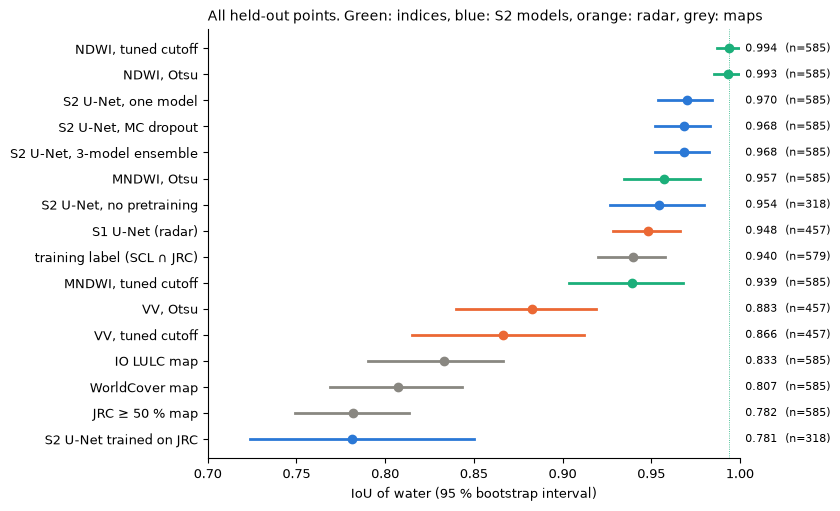

In [2]:
order = ["ndwi_tuned", "ndwi_otsu", "single", "mc_mean", "ens_mean", "mndwi_otsu",
         "rand_init", "s1", "weak_scl_jrc", "mndwi_tuned", "vv_otsu", "vv_tuned",
         "weak_io_lulc", "weak_worldcover", "weak_jrc50", "jrc50_label"]
names = {"mndwi_tuned": "MNDWI, tuned cutoff", "mndwi_otsu": "MNDWI, Otsu",
         "ndwi_otsu": "NDWI, Otsu", "single": "S2 U-Net, one model", "mc_mean": "S2 U-Net, MC dropout",
         "ens_mean": "S2 U-Net, 3-model ensemble", "weak_scl_jrc": "training label (SCL ∩ JRC)",
         "s1": "S1 U-Net (radar)", "rand_init": "S2 U-Net, no pretraining", "vv_otsu": "VV, Otsu",
         "vv_tuned": "VV, tuned cutoff", "weak_io_lulc": "IO LULC map",
         "weak_worldcover": "WorldCover map", "jrc50_label": "S2 U-Net trained on JRC",
         "weak_jrc50": "JRC ≥ 50 % map", "ndwi_tuned": "NDWI, tuned cutoff"}
d = m[m.group == "all_heldout"].set_index("method").loc[order]
kind = lambda k: ORANGE if k in ("s1", "vv_otsu", "vv_tuned") else BLUE if k in (
    "single", "mc_mean", "ens_mean", "rand_init", "jrc50_label") else GREEN if "ndwi" in k else GREY
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for i, (k, r) in enumerate(d.iterrows()):
    ax.plot([r.iou_lo, r.iou_hi], [i, i], color=kind(k), lw=2)
    ax.plot(r.iou, i, "o", color=kind(k), ms=6)
    ax.text(1.003, i, f"{r.iou:.3f}  (n={int(r.n)})", va="center", fontsize=8)
ax.set_yticks(range(len(order)), [names[k] for k in order])
ax.invert_yaxis()
ax.set(xlim=(0.7, 1.0), xlabel="IoU of water (95 % bootstrap interval)",
       title="All held-out points. Green: indices, blue: S2 models, orange: radar, grey: maps")
ax.axvline(d.loc["ndwi_tuned", "iou"], color=GREEN, lw=0.6, ls=":")
plt.tight_layout()

NDWI, tuned or Otsu, sits on top at about 0.99. The three U-Net variants follow at about 0.97,
then MNDWI. The intervals are ±0.01-0.03 and overlap, so this chart alone can't say whether
the gaps are real.

## Paired comparisons: the right tool for "is A better than B?"

Both methods were scored on the *same* points. A hard point (a muddy shoreline pixel) tends to
trip both methods up, an easy one neither. Comparing two separate intervals ignores that shared
difficulty and is far too conservative. The right question is about the **difference on the
same resampled points**: resample points, compute IoU(A) − IoU(B) on that sample, repeat.

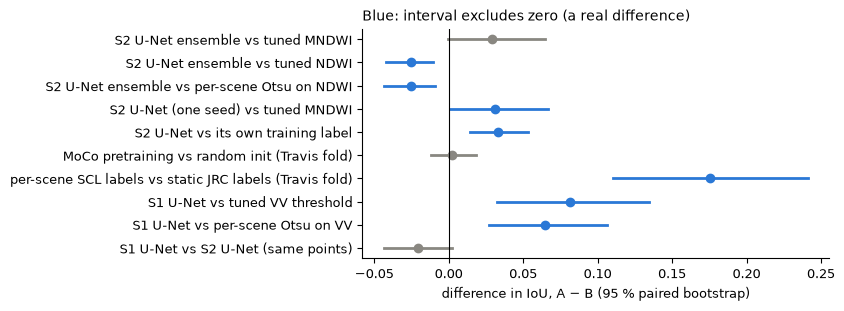

In [3]:
pdiff = pd.read_csv(C.RESULTS_DIR / "paired_differences.csv")
pd_ = pdiff[pdiff.group == "all_heldout"].copy()
fig, ax = plt.subplots(figsize=(8.5, 3.2))
for i, r in enumerate(pd_.itertuples()):
    c = BLUE if r.d_iou_lo > 0 or r.d_iou_hi < 0 else GREY
    ax.plot([r.d_iou_lo, r.d_iou_hi], [i, i], color=c, lw=2)
    ax.plot(r.d_iou, i, "o", color=c)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(pd_)), pd_.question)
ax.invert_yaxis()
ax.set(xlabel="difference in IoU, A − B (95 % paired bootstrap)",
       title="Blue: interval excludes zero (a real difference)")
plt.tight_layout()

Now the picture is clear:

* **S2 U-Net vs tuned NDWI: −0.026, interval [−0.042, −0.011].** A real difference, in NDWI's
  favour. Per-scene Otsu on NDWI, which needs no labels at all, also beats the U-Net.
* **S2 U-Net vs tuned MNDWI: +0.029, interval [−0.000, +0.065].** The U-Net is probably
  ahead of MNDWI (it won in 97 % of resamples), but the interval just touches zero.
* **Label choice (+0.175)** and **S1 U-Net vs radar thresholds (+0.07-0.08)** are real, large
  effects.
* **Pretraining (+0.003)** makes no detectable difference.

### What this does and doesn't mean

**On clear-sky Sentinel-2 imagery of open reservoir water, judged one 10 m pixel at a time**,
a one-line NDWI threshold is more accurate than the U-Net. Three things keep that from being
a general verdict on deep learning:

1. **Ceiling effect.** Everything good is above 0.96, so the race is decided by a couple of
   dozen pixels.
2. **Where the points are.** Only 22 of the 585 points get different answers from the U-Net
   and NDWI (table below), almost all on the shoreline. NDWI is right on 19 of them.
3. **What the test rewards.** Each label judges a single 10 m pixel, usually at the water's
   edge. NDWI uses only 10 m bands. MNDWI and the U-Net also lean on 20 m short-wave infrared
   bands, and the U-Net looks at neighbouring pixels too. A pixel-exact shoreline test favours
   the sharpest method. That is a genuine strength, but it isn't the same as measuring lake
   area well (notebook 7).

The points where the U-Net is wrong aren't random either. Looking through them, they fall
into two groups: lakebed that was usually under water but was dry on that date, which the
U-Net still calls water, and water in places that are usually dry (the 2018 flood, the 2026
refills), which it misses. Both errors pull towards the lake's *usual* outline. The model
learned from labels that included the JRC water history (notebook 3), and some of that
history leaks into its answers.

In [4]:
ens = (pts.p_ens_mean > 0.5).astype(int)
for col, nm in (("pred_ndwi_tuned", "NDWI"), ("pred_mndwi_tuned", "MNDWI")):
    other = pts[col].astype(int)
    dis = pts[ens != other]
    print(f"points where U-Net and tuned {nm} disagree: {len(dis)} of {len(pts)}")
    print(pd.crosstab(dis.stratum, np.where((dis.p_ens_mean > 0.5) == dis.label.astype(bool),
                                            "U-Net right", f"{nm} right")), "\n")

points where U-Net and tuned NDWI disagree: 22 of 585
col_0    NDWI right  U-Net right
stratum                         
B                17            3
C                 2            0 

points where U-Net and tuned MNDWI disagree: 23 of 585
col_0    MNDWI right  U-Net right
stratum                          
A                  0            2
B                  9           10
C                  1            1 



## Can the model's confidence be trusted?

A model that says "p = 0.9" should be right about 90 % of the time when it says so. That is
**calibration**, and it matters for uncertainty maps: if the probabilities are honest, the
shoreline band of intermediate values really is where the map is unsure.

We check it on the hand points, weighting each point by the pixels it stands for. The
probabilities are piled up at 0 and 1, so we use four bins with confidence intervals rather
than ten mostly empty ones.

p_ens_mean   weighted ECE = 0.006
p_mc_mean    weighted ECE = 0.007
p_s1         weighted ECE = 0.015


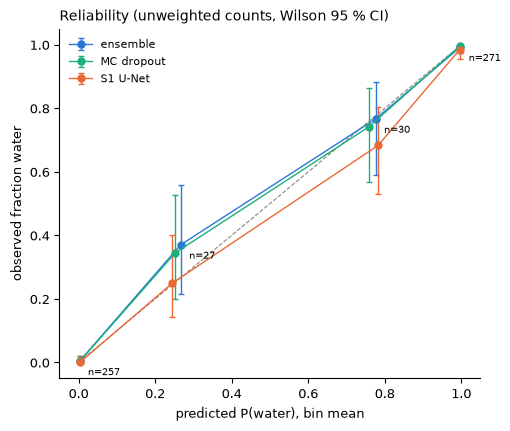

In [5]:
def wilson(k, n, z=1.96):
    """Wilson score interval for a proportion k/n (better than ±1.96·se for small n)."""
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h


edges = [0, 0.05, 0.5, 0.95, 1.0001]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.plot([0, 1], [0, 1], color=GREY, lw=0.8, ls="--")
for col, c, lab in (("p_ens_mean", BLUE, "ensemble"), ("p_mc_mean", GREEN, "MC dropout"),
                    ("p_s1", ORANGE, "S1 U-Net")):
    d_ = pts[pts[col].notna()]
    b = np.digitize(d_[col], edges) - 1
    xs, ys, lo, hi, ns = [], [], [], [], []
    for k in range(4):
        s = d_[b == k]
        if len(s) == 0:
            continue
        xs.append(s[col].mean())
        ys.append(s.label.mean())
        a, z = wilson(s.label.sum(), len(s))
        lo.append(ys[-1] - a)
        hi.append(z - ys[-1])
        ns.append(len(s))
    ax.errorbar(xs, ys, yerr=[lo, hi], fmt="o-", color=c, ms=5, lw=1, capsize=2, label=lab)
    if col == "p_ens_mean":
        for x, y, n in zip(xs, ys, ns):
            ax.annotate(f"n={n}", (x, y), textcoords="offset points", xytext=(6, -10), fontsize=7.5)
for col in ("p_ens_mean", "p_mc_mean", "p_s1"):
    d_ = pts[pts[col].notna()]
    e, _ = ece(d_[col].values, d_.label.values.astype(float), d_.w.values)
    print(f"{col:12s} weighted ECE = {e:.3f}")
ax.set(xlabel="predicted P(water), bin mean", ylabel="observed fraction water",
       title="Reliability (unweighted counts, Wilson 95 % CI)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

The expected calibration error (ECE) is under 0.01, which sounds excellent, but it is almost
entirely made of points at p ≈ 0 and p ≈ 1, where the model is confidently right. The
interesting bins are the middle ones, and they hold only 57 points. There the ensemble is
**close to honest**: points it scores at about 0.27 are water 37 % of the time, and points it
scores at about 0.78 are water 77 % of the time. The intervals are wide (few points), so
"no detectable miscalibration" is the fair summary, not "perfect".

This is another result where the two answer keys differ. Against the AI labels, the middle
bins look over-confident in both directions. Most of the points that made them look that way were
shoreline pixels the AI had marked unsure, or called differently from the person.
A single average can hide the behaviour you care about, so look at the bins, and know that the
bins are only as good as the labels in them.

## Does uncertainty point at errors?

The more practical test: if we flag the pixels where the ensemble members disagree most, do we
catch the mistakes?

ensemble errors: 20 of 585 points
mean ensemble std on correct points: 0.006, on wrong points: 0.069
AUROC, ensemble std as an error detector:    0.951
AUROC, MC-dropout std as an error detector:  0.940


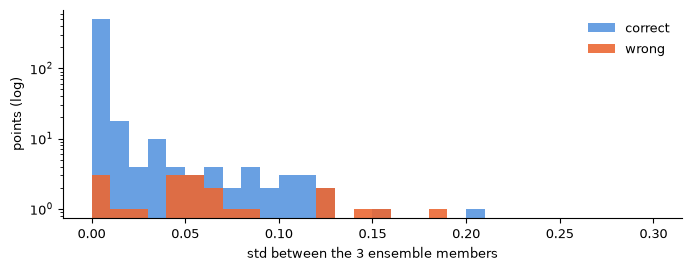

In [6]:
from hlw.evaluate import _auroc as roc_auc_score  # rank-based AUROC, no sklearn needed  # noqa: E402

wrong = ((pts.p_ens_mean > 0.5) != pts.label.astype(bool)).astype(int)
print(f"ensemble errors: {wrong.sum()} of {len(pts)} points")
print(f"mean ensemble std on correct points: {pts.p_ens_std[wrong == 0].mean():.3f}, "
      f"on wrong points: {pts.p_ens_std[wrong == 1].mean():.3f}")
print(f"AUROC, ensemble std as an error detector:    {roc_auc_score(pts.p_ens_std.values, wrong.values):.3f}")
print(f"AUROC, MC-dropout std as an error detector:  {roc_auc_score(pts.p_mc_std.values, wrong.values):.3f}")

fig, ax = plt.subplots(figsize=(7, 2.8))
bins = np.linspace(0, 0.3, 31)
ax.hist(pts.p_ens_std[wrong == 0], bins=bins, color=BLUE, alpha=0.7, label="correct", log=True)
ax.hist(pts.p_ens_std[wrong == 1], bins=bins, color=ORANGE, alpha=0.9, label="wrong", log=True)
ax.set(xlabel="std between the 3 ensemble members", ylabel="points (log)")
ax.legend(frameon=False)
plt.tight_layout()

Yes, strongly. Errors almost never happen where the members agree, and wrong points have about
10× the spread of correct ones. Used as an error detector, the ensemble spread scores an AUROC
of about 0.95. That's the practical value of the uncertainty map: it tells a user **which
stretches of shoreline to distrust**. A plain index threshold gives no such signal.

The ensemble's spread works slightly better than MC dropout's (AUROC 0.95 vs 0.94) and costs
three training runs instead of one. Both are cheap at this scale.

## Takeaways

* Compare methods with **paired** intervals on shared test data. Separate intervals are too
  blunt.
* A close race at the ceiling is a statement about the test, not only about the methods. Ask
  where the test points sit, what scale they judge, and which ones were dropped.
* Look at the points a model gets wrong. Here they revealed a systematic pull towards the
  lake's usual outline.
* Check calibration **bin by bin**. A tiny ECE can hide over-confidence exactly where
  uncertainty matters.
* Ensemble disagreement is a cheap, effective pointer to likely errors.

Next: [7 · area, level and radar](07_area_level_radar.ipynb)